# Stochastic scenario risk

Public aggregate scenario results from correlated geometric Brownian motion and historical block resampling. These are conditional hypothetical outcomes, not live investment returns or proof of future alpha.


In [4]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
here=Path.cwd().resolve()
ROOT=next((p for p in (here,*here.parents) if (p/'results/rolling_forecast_accuracy.csv').exists()),None)
if ROOT is None: raise FileNotFoundError('Run notebook from the public repository or its notebooks directory')


## Portfolio stress benchmarks

All reported terminal-wealth figures start from 10,000. Compare portfolios within a scenario generator, not as independent statistical validation.


,portfolio,model,median_terminal_wealth_10000,p05_terminal_wealth_10000,p05_max_drawdown,probability_underperform_spy,median_spy_wealth_10000
0,joint_l2,GBM,12248.1300,9003.6195,-0.1970,0.177,11184.2074
1,joint_l2,Joint block bootstrap,12525.6596,9061.3138,-0.2502,0.079,11302.1929
2,joint_elastic_net,GBM,12189.8453,8981.0470,-0.2006,0.188,11184.2074
3,joint_elastic_net,Joint block bootstrap,12479.1004,9025.8838,-0.2522,0.094,11302.1929
4,equal_all,GBM,11197.5213,8914.3630,-0.1744,0.504,11184.2074
5,equal_all,Joint block bootstrap,11304.9379,9250.8231,-0.1759,0.493,11302.1929


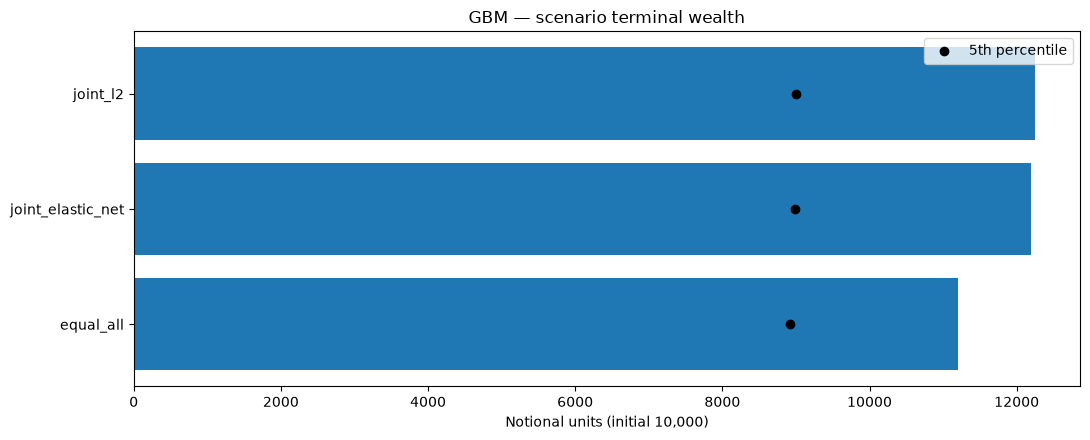

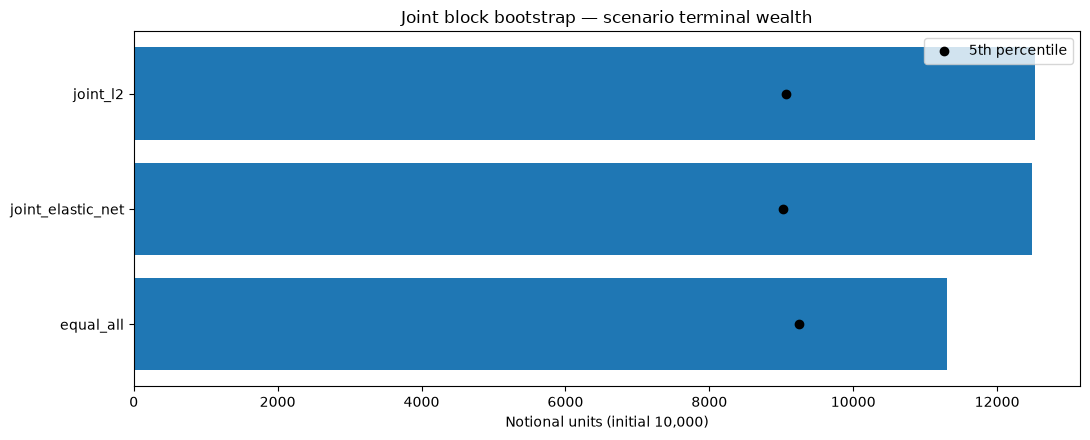

In [5]:
stress=pd.read_csv(ROOT/'results/scenario_stress_summary.csv')
display(stress.round(4))
for method,g in stress.groupby('model'):
    g=g.sort_values('median_terminal_wealth_10000')
    fig,ax=plt.subplots(figsize=(11,4.5))
    x=np.arange(len(g));lo=g.p05_terminal_wealth_10000.to_numpy();med=g.median_terminal_wealth_10000.to_numpy()
    ax.barh(g.portfolio,med);ax.scatter(lo,np.arange(len(g)),label='5th percentile',color='black',zorder=3)
    ax.set_title(str(method)+' — scenario terminal wealth');ax.set_xlabel('Notional units (initial 10,000)');ax.legend();fig.tight_layout();plt.show()


## Downside and benchmark dependence

The 5th-percentile drawdown and relative-SPY risk are summaries of simulated scenarios. Individual simulated paths and private strategy parameters are not provided.


In [6]:
cols=[c for c in ['portfolio','model','p05_max_drawdown','probability_underperform_spy','median_spy_wealth_10000'] if c in stress.columns]
display(stress[cols].sort_values(['model','portfolio']).round(4))


,portfolio,model,p05_max_drawdown,probability_underperform_spy,median_spy_wealth_10000
4,equal_all,GBM,-0.1744,0.504,11184.2074
2,joint_elastic_net,GBM,-0.2006,0.188,11184.2074
0,joint_l2,GBM,-0.1970,0.177,11184.2074
5,equal_all,Joint block bootstrap,-0.1759,0.493,11302.1929
3,joint_elastic_net,Joint block bootstrap,-0.2522,0.094,11302.1929
1,joint_l2,Joint block bootstrap,-0.2502,0.079,11302.1929


## Interpretation

Simulation calibrations may embed estimated drift and correlation relationships that do not persist. Fixed holdings and Gaussian shocks do not reproduce dynamic portfolio refitting, market impact, or changing accounting information.
